# **PROJETO STP - M5 Forescasting**

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

# **Phase 1 - Statistical Models - Baseline Models**

O presente projeto tem como objetivo analisar e modelar séries temporais de vendas do dataset M5, com foco na compreensão dos padrões subjacentes e na sua capacidade preditiva. Numa primeira fase, realizamos uma análise exploratória detalhada, incluindo estatísticas descritivas, avaliação de tendência, sazonalidade e estacionariedade. Posteriormente, esses insights são utilizados para suportar a escolha e aplicação de modelos de previsão adequados. De anotar que o modelo AutoARIMA conta ainda com a inclusão de regressores. No final do projeto, comparamos todos os modelos instanciados e estudamos qual o melhor.

| __*Feature*__ | __Descrição__ |
| :--- | :--- |
| __unique_id__ | Identificador da série temporal. |
| __ds__ | Variável temporal (*date stamp*). |
| __y__ | Variável target. |

---

## **1. Imports and Data Upload**

In [ ]:
!pip install statsforecast

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.6/354.6 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 4.8 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from statsforecast import StatsForecast
from statsforecast.models import (
    Naive,
    SeasonalNaive,
    HistoricAverage,
    RandomWalkWithDrift
)

from sklearn import metrics

In [ ]:
base_url = 'https://datasets-nixtla.s3.amazonaws.com'
Y_df = pd.read_parquet(f'{base_url}/m5_y.parquet')
Y_df

,unique_id,ds,y
0,FOODS_1_001_CA_1,2011-01-29,3.0
1,FOODS_1_001_CA_1,2011-01-30,0.0
2,FOODS_1_001_CA_1,2011-01-31,0.0
3,FOODS_1_001_CA_1,2011-02-01,1.0
4,FOODS_1_001_CA_1,2011-02-02,4.0
...,...,...,...
47649935,HOUSEHOLD_2_516_WI_3,2016-06-15,0.0
47649936,HOUSEHOLD_2_516_WI_3,2016-06-16,1.0
47649937,HOUSEHOLD_2_516_WI_3,2016-06-17,0.0
47649938,HOUSEHOLD_2_516_WI_3,2016-06-18,0.0


In [ ]:
uids = Y_df['unique_id'].unique()
uids

['FOODS_1_001_CA_1', 'FOODS_1_001_CA_2', 'FOODS_1_001_CA_3', 'FOODS_1_001_CA_4', 'FOODS_1_001_TX_1', ..., 'HOUSEHOLD_2_516_TX_2', 'HOUSEHOLD_2_516_TX_3', 'HOUSEHOLD_2_516_WI_1', 'HOUSEHOLD_2_516_WI_2', 'HOUSEHOLD_2_516_WI_3']
Length: 30490
Categories (30490, object): ['FOODS_1_001_CA_1', 'FOODS_1_001_CA_2', 'FOODS_1_001_CA_3',
                             'FOODS_1_001_CA_4', ..., 'HOUSEHOLD_2_516_TX_3', 'HOUSEHOLD_2_516_WI_1',
                             'HOUSEHOLD_2_516_WI_2', 'HOUSEHOLD_2_516_WI_3']

## **2. Escolha do departamento**

In [ ]:
departments = pd.Series(uids).str.split("_").str[:2].str.join("_")
num_departments = departments.nunique()

print("Número de departamentos:", num_departments)
print("Departamentos:", departments.unique())

Número de departamentos: 7
Departamentos: ['FOODS_1' 'FOODS_2' 'FOODS_3' 'HOBBIES_1' 'HOBBIES_2' 'HOUSEHOLD_1'
 'HOUSEHOLD_2']


In [ ]:
stores = pd.Series(uids).str.split("_").str[3:5].str.join("_")
num_stores = stores.nunique()

print("Número de lojas:", num_stores)
print("Lojas:", stores.unique())

Número de lojas: 10
Lojas: ['CA_1' 'CA_2' 'CA_3' 'CA_4' 'TX_1' 'TX_2' 'TX_3' 'WI_1' 'WI_2' 'WI_3']


Departamento escolhido: ***HOUSEHOLD 2 da loja TX_1*** - 149 séries temporais

In [ ]:
Y_df_HOBBIES_2 = Y_df[Y_df['unique_id'].str.startswith('HOBBIES_2')]
Y_df_HOBBIES_2_TX1 = Y_df_HOBBIES_2[Y_df_HOBBIES_2['unique_id'].str.endswith('TX_1')]
Y_df_HOBBIES_2_TX1

,unique_id,ds,y
28860162,HOBBIES_2_001_TX_1,2011-02-11,1.0
28860163,HOBBIES_2_001_TX_1,2011-02-12,0.0
28860164,HOBBIES_2_001_TX_1,2011-02-13,0.0
28860165,HOBBIES_2_001_TX_1,2011-02-14,0.0
28860166,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
31097066,HOBBIES_2_149_TX_1,2016-06-15,0.0
31097067,HOBBIES_2_149_TX_1,2016-06-16,0.0
31097068,HOBBIES_2_149_TX_1,2016-06-17,0.0
31097069,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [ ]:
Y_df_HOBBIES_2_TX1.to_csv("HOBBIES_2_TX1.csv", index=False)

In [ ]:
train = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] <= '2016-05-22']
train

,unique_id,ds,y
28860162,HOBBIES_2_001_TX_1,2011-02-11,1.0
28860163,HOBBIES_2_001_TX_1,2011-02-12,0.0
28860164,HOBBIES_2_001_TX_1,2011-02-13,0.0
28860165,HOBBIES_2_001_TX_1,2011-02-14,0.0
28860166,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
31097038,HOBBIES_2_149_TX_1,2016-05-18,3.0
31097039,HOBBIES_2_149_TX_1,2016-05-19,0.0
31097040,HOBBIES_2_149_TX_1,2016-05-20,0.0
31097041,HOBBIES_2_149_TX_1,2016-05-21,1.0


In [ ]:
test = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] > '2016-05-22']
test

,unique_id,ds,y
28862090,HOBBIES_2_001_TX_1,2016-05-23,0.0
28862091,HOBBIES_2_001_TX_1,2016-05-24,0.0
28862092,HOBBIES_2_001_TX_1,2016-05-25,0.0
28862093,HOBBIES_2_001_TX_1,2016-05-26,0.0
28862094,HOBBIES_2_001_TX_1,2016-05-27,0.0
...,...,...,...
31097066,HOBBIES_2_149_TX_1,2016-06-15,0.0
31097067,HOBBIES_2_149_TX_1,2016-06-16,0.0
31097068,HOBBIES_2_149_TX_1,2016-06-17,0.0
31097069,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [ ]:
train.shape, test.shape

((217559, 3), (4172, 3))

## **3. Exploratory Data Analysis**


### **3.1. Análise descritiva**

In [ ]:
### ---1. ANÁLISE DOS DATASETS--- ###

print("----- ANÁLISE DOS DATASETS -----\n")

# Forma do dataset
print("----- Forma do dataset -----")
print(f"train shape:   {train.shape}")
print(f"test shape:    {test.shape}\n")

# Tipos de dados
print("----- Tipo de dados do dataset -----")
print("train dtypes:")
print(train.dtypes, "\n")

print("test dtypes:")
print(test.dtypes, "\n")

# Estatísticas descritivas
print("----- Dados descritivos do dataset -----")
print("train describe:")
print(train.describe(), "\n")

print("test describe:")
print(test.describe(), "\n")

# Duplicados
print("----- Duplicados do dataset -----")
print(f"train duplicados:   {train.duplicated().sum()}")
print(f"test duplicados:    {test.duplicated().sum()}\n")

# Nulos por coluna
print("----- Nulos por coluna -----")
print("train:")
print(train.isnull().sum(), "\n")

print("test:")
print(test.isnull().sum(), "\n")

# Total de nulos
print("----- Total de nulos -----")
print(f"train total de nulos:   {train.isnull().sum().sum()}")
print(f"test total de nulos:    {test.isnull().sum().sum()}")


----- ANÁLISE DOS DATASETS -----

----- Forma do dataset -----
train shape:   (217559, 3)
test shape:    (4172, 3)

----- Tipo de dados do dataset -----
train dtypes:
unique_id          category
ds           datetime64[ns]
y                   float32
dtype: object 

test dtypes:
unique_id          category
ds           datetime64[ns]
y                   float32
dtype: object 

----- Dados descritivos do dataset -----
train describe:
                                  ds              y
count                         217559  217559.000000
mean   2014-02-24 21:36:26.568241152       0.203614
min              2011-01-29 00:00:00       0.000000
25%              2012-12-28 00:00:00       0.000000
50%              2014-05-13 00:00:00       0.000000
75%              2015-05-23 00:00:00       0.000000
max              2016-05-22 00:00:00      43.000000
std                              NaN       0.727684 

test describe:
                        ds            y
count                 4172  4172.00000

A análise descritiva revela-nos que o conjunto de treino contém 217.559 observações, enquanto o conjunto de teste apresenta 4.172 registos. Os conjuntos possuem três variáveis: `unique_id` (identificador da série temporal), `ds` (variável temporal) e `y` (variável alvo, representativa das vendas).

Relativamente aos tipos de dados, verificamos que o `unique_id` está corretamente definido como categórico, `ds` como variável temporal (datetime64), e `y` como variável numérica (float32), o que é adequado para tarefas de previsão de séries temporais.

No que diz respeito à variável temporal, o dataset de treino cobre o período entre janeiro de 2011 e maio de 2016, enquanto o conjunto de teste corresponde ao intervalo imediatamente seguinte (maio a junho de 2016 - os últimos 28 dias do dataset original).

A análise estatística da variável `y` evidencia uma distribuição altamente assimétrica e concentrada em zero. Em ambos os datasets, os quartis (25%, 50% e 75%) apresentam valor zero, indicando que a maioria das observações corresponde à ausência de vendas. Apesar disso, existem valores máximos relativamente elevados (43 no treino e 10 no teste), o que sugere a presença de picos ocasionais de procura.

A média das vendas é baixa (aproximadamente 0.20 no treino e 0.23 no teste), o que reforça a ideia de um padrão de vendas esporádico e irregular. O desvio padrão relativamente superior à média confirma-nos a elevada variabilidade dos dados, típica de séries temporais com grande dispersão e muitos zeros.

Adicionalmente, não há valores duplicados nem valores em falta.

### **3.2. Análise de tendência e estacionaridade**

Embora o departamento contenha 149 séries, optamos por analisar apenas uma série como exemplo, de forma a ilustrar os padrões temporais sem sobrecarregar a memória do sistema ou dificultar a interpretação visual. Escolhemos como representativa a primeira série: `HOBBIES_2_001_TX_1`.

A análise será feita em várias etapas: primeiro, aplicamos uma média móvel de 30 dias para suavizar as flutuações diárias e evidenciar a tendência subjacente, sem apagar a sazonalidade semanal presente nos dados. Posteriormente, realizamos a decomposição aditiva da série em tendência, sazonalidade e componente residual, permitindo separar e visualizar cada padrão. Por fim, aplicamos o teste Augmented Dickey-Fuller para avaliar a estacionariedade da série, confirmando se a tendência e/ou sazonalidade identificadas são estatisticamente relevantes e justificando a consideração destas características nos modelos de previsão subsequentes.

In [ ]:
# Seleção da série representativa

serie_ex = train[train['unique_id'] == 'HOBBIES_2_001_TX_1'].set_index('ds')['y']

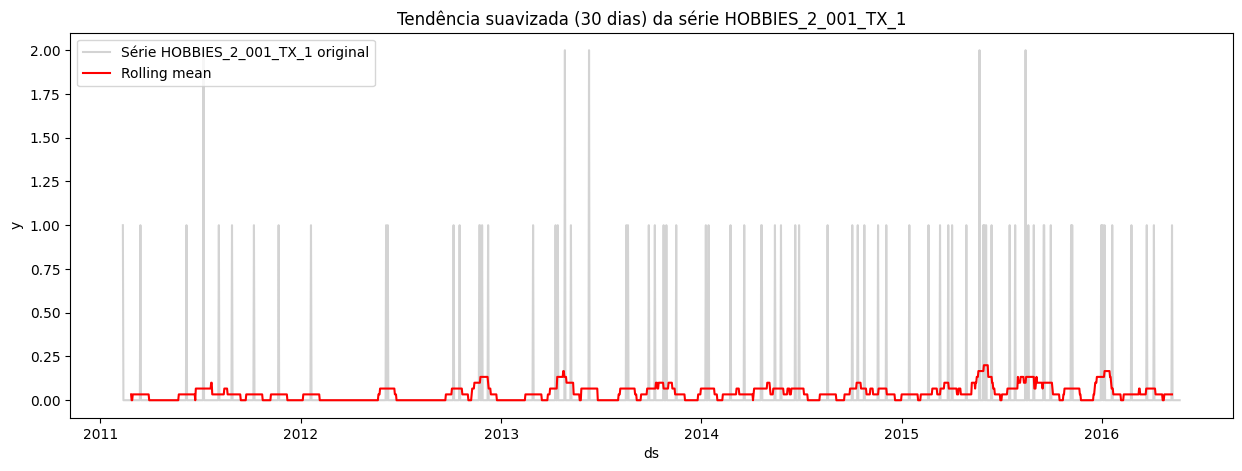

In [ ]:
# ROLLING MEAN

serie_roll30 = serie_ex.rolling(window=30, center=True).mean()

plt.figure(figsize=(15,5))
plt.plot(serie_ex, color='lightgray', label='Série HOBBIES_2_001_TX_1 original')
plt.plot(serie_roll30, color='red', label='Rolling mean')
plt.title('Tendência da série HOBBIES_2_001_TX_1')
plt.xlabel('ds')
plt.ylabel('y')
plt.legend()
plt.show()

A média móvel de 30 dias mostra-nos uma tendência global estável e próxima de zero, com pequenas oscilações pontuais. Não se observa uma tendência clara de crescimento ou queda ao longo do tempo.

Este comportamento reflete a natureza intermitente da série, dominada por valores nulos e picos ocasionais, sem estrutura de longo prazo evidente.

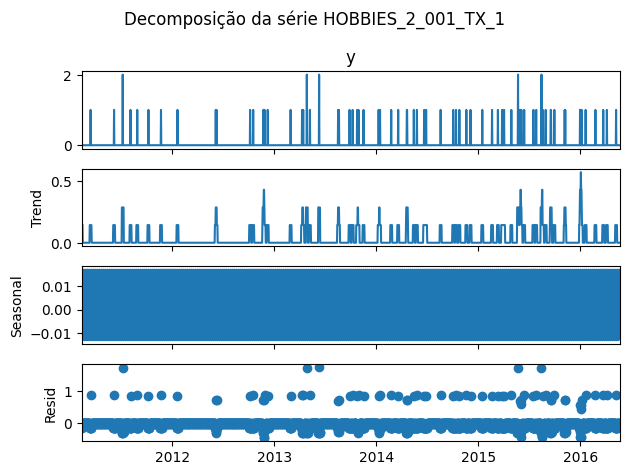

In [ ]:
# DECOMPOSIÇÃO

decomposed = seasonal_decompose(serie_ex, model='add', period=7)

decomposed.plot()
plt.suptitle('Decomposição da série HOBBIES_2_001_TX_1')
plt.tight_layout()
plt.show()

A componente de tendência mantém-se baixa e irregular, sem padrão definido. A componente sazonal não evidencia um comportamento consistente, sugerindo ausência de sazonalidade relevante.

A maior parte da variabilidade está concentrada na componente residual, indicando que a série é dominada por flutuações aleatórias e eventos esporádicos.

In [ ]:
# AUGMENTED DICKEY-FULLER TEST

result = adfuller(serie_ex)

print("ADF Statistic:", result[0])
print("p-value:", result[1])
if result[1] < 0.05:
    print("Série estacionária (p < 0.05)")
else:
    print("Série não estacionária (p >= 0.05) – presença de tendência ou sazonalidade")

ADF Statistic: -43.78645158575578
p-value: 0.0
Série estacionária (p < 0.05)


O teste ADF (estatística = -43.79; p-value = 0.0) indica que a série é estacionária.

No entanto, este resultado deve ser interpretado com cautela, pois a elevada presença de zeros pode influenciar o teste, levando a uma estacionariedade aparente.

### **3.3. Análise de sazonalidade e autocorrelação**

Para explorar padrões de dependência temporal e sazonalidade, faremos uso dos gráficos de autocorrelação (ACF) e autocorrelação parcial (PACF), que permitem identificar a força e a duração da relação da série consigo mesma em diferentes *lags*. O objetivo desta análise é evidenciar padrões repetitivos, como ciclos semanais ou mensais, que fornecem informação útil para a modelagem futura com os modelos de previsão. A escolha de uma única série é deliberada, tal como explicado acima, de forma a evitar sobrecarga de memória e garantir clareza visual nos gráficos.

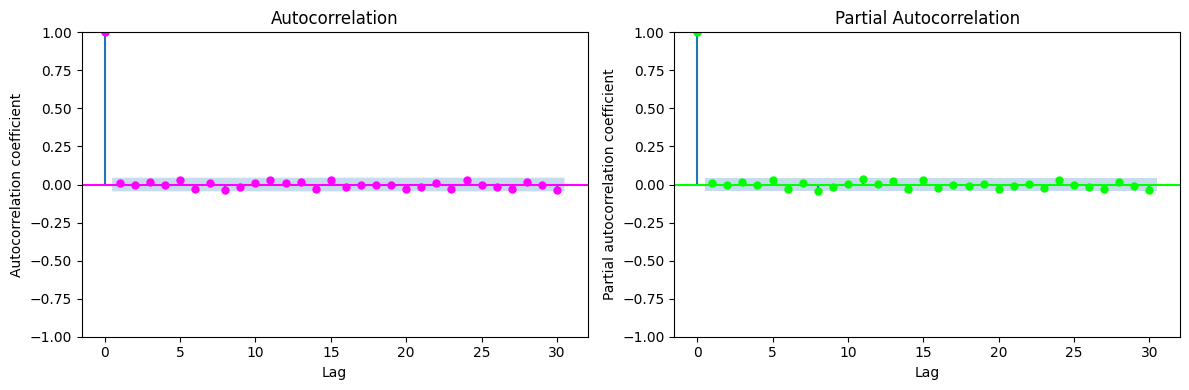

In [ ]:
# ACF e PACF

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

plot_acf(serie_ex, lags=30, ax=axs[0], color="fuchsia")
axs[0].set_title("Autocorrelation")
axs[0].set_xlabel("Lag")
axs[0].set_ylabel("Autocorrelation coefficient")

plot_pacf(serie_ex, lags=30, ax=axs[1], color="lime")
axs[1].set_title("Partial Autocorrelation")
axs[1].set_xlabel("Lag")
axs[1].set_ylabel("Partial autocorrelation coefficient")

plt.tight_layout()
plt.show()

O gráfico de ACF mostra que, para além do *lag* 0, os coeficientes de autocorrelação são muito próximos de zero e encontram-se dentro do intervalo de confiança. Isto indica ausência de dependência temporal significativa entre observações.

Não se identificam picos relevantes em *lags* específicos, o que sugere que não existem padrões sazonais claros (como ciclos semanais ou mensais).

O gráfico de PACF apresenta um comportamento semelhante ao ACF, com coeficientes próximos de zero para praticamente todos os *lags*. Não se observam cortes abruptos ou *lags* dominantes.

Este resultado reforça a ausência de estrutura autoregressiva relevante na série.

## **4. Statistical Models implementation**


Avançando para o *modeling*, aplicamos diferentes modelos de previsão com o objetivo de estimar os valores futuros da série temporal num horizonte de 28 dias. Considerando a frequência diária dos dados (`freq = 'D'`), foi definida uma sazonalidade semanal (`season_length = 7`), de forma a capturar possíveis padrões ao longo da semana.

No início desta fase do projeto utilizamos 4 baseline models, nomeadamente: **Naive, Seasonal Naive, Historic Average e Random Walk with Drift**. Estes modelos simples permitem estabelecer uma referência inicial de desempenho para comparação com abordagens mais avançadas.

A implementação é feita com recurso à biblioteca StatsForecast, incluindo a geração de intervalos de previsão com nível de confiança de 95%.

Por fim, para facilitar a interpretação visual, comparamos as previsões e os valores reais nos últimos 40 dias do conjunto de treino.

In [ ]:
freq = 'D'
season_length = 7
horizon = 28

In [ ]:
models = [
    Naive(),
    SeasonalNaive(season_length=season_length),
    HistoricAverage(),
    RandomWalkWithDrift()
]

In [ ]:
sf = StatsForecast(
    models=models,
    freq=freq,
    n_jobs=-1
)

In [ ]:
levels = [95]

forecasts = sf.forecast(df=train, h=horizon, level=levels)

forecasts

,unique_id,ds,Naive,Naive-lo-95,Naive-hi-95,SeasonalNaive,SeasonalNaive-lo-95,SeasonalNaive-hi-95,HistoricAverage,HistoricAverage-lo-95,HistoricAverage-hi-95,RWD,RWD-lo-95,RWD-hi-95
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,-0.587260,0.587260,0.0,-0.588176,0.588176,0.042012,-0.375976,0.460001,-0.000519,-0.587930,0.586892
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,-0.830511,0.830511,0.0,-0.588176,0.588176,0.042012,-0.375976,0.460001,-0.001038,-0.831978,0.829902
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,-1.017164,1.017164,0.0,-0.588176,0.588176,0.042012,-0.375976,0.460001,-0.001557,-1.019511,1.016397
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,-1.174520,1.174520,0.0,-0.588176,0.588176,0.042012,-0.375976,0.460001,-0.002076,-1.177812,1.173660
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,-1.313153,1.313153,0.0,-0.588176,0.588176,0.042012,-0.375976,0.460001,-0.002595,-1.317448,1.312259
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.0,-9.549828,9.549828,3.0,-1.271338,7.271338,0.302158,-1.268100,1.872416,-0.021602,-9.674023,9.630818
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,-9.746752,9.746752,0.0,-4.271338,4.271338,0.302158,-1.268100,1.872416,-0.022502,-9.878302,9.833297
4169,HOBBIES_2_149_TX_1,2016-06-17,0.0,-9.939775,9.939775,0.0,-4.271338,4.271338,0.302158,-1.268100,1.872416,-0.023402,-10.078808,10.032002
4170,HOBBIES_2_149_TX_1,2016-06-18,0.0,-10.129122,10.129122,1.0,-3.271338,5.271338,0.302158,-1.268100,1.872416,-0.024302,-10.275762,10.227157


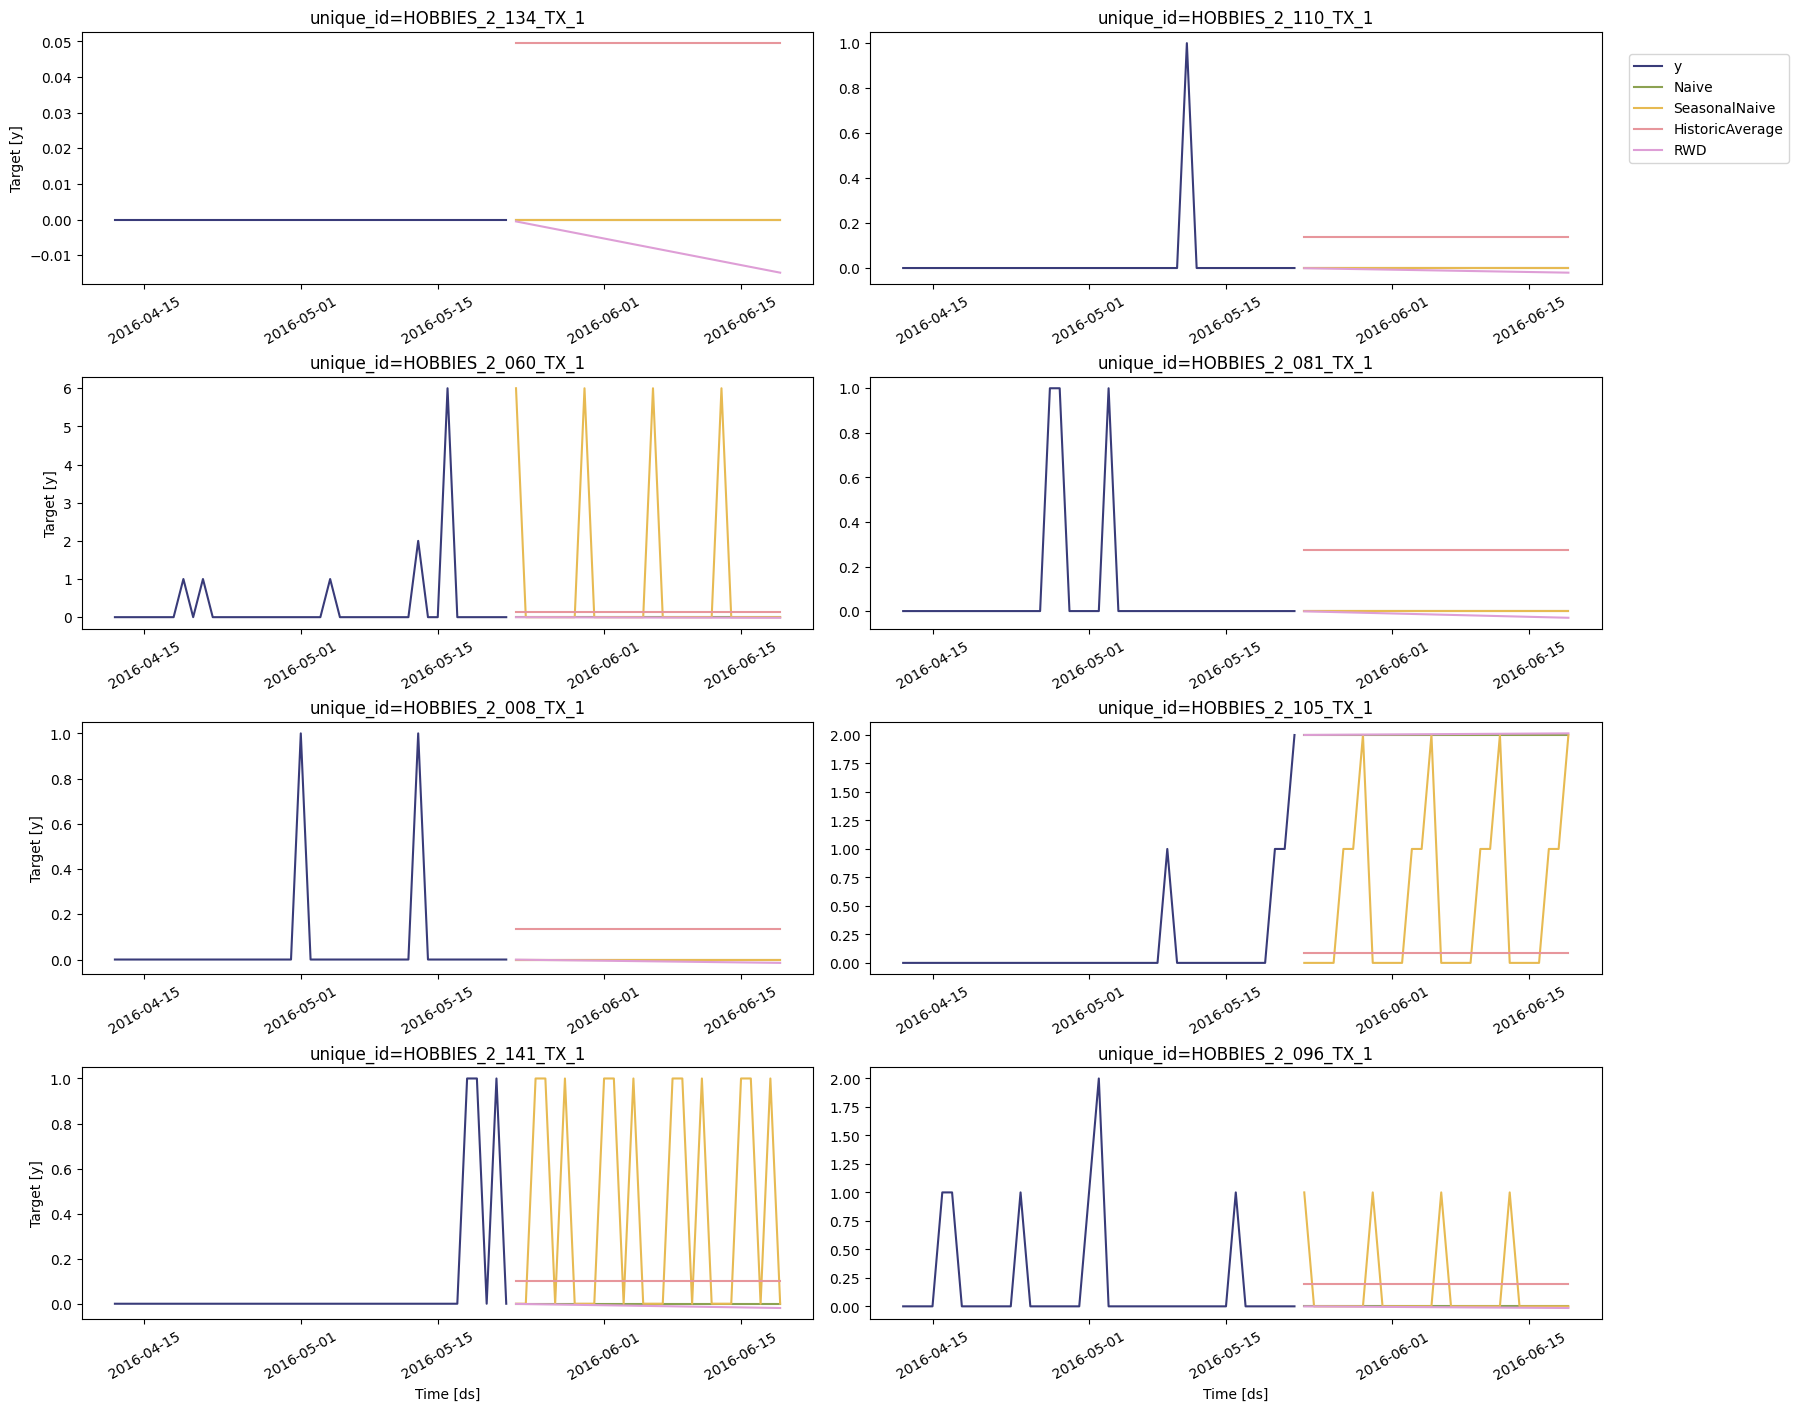

In [ ]:
cutoff = train["ds"].max() - pd.Timedelta(days=40)
train_last_40_days = train[train["ds"] >= cutoff]

sf.plot(train_last_40_days, forecasts)

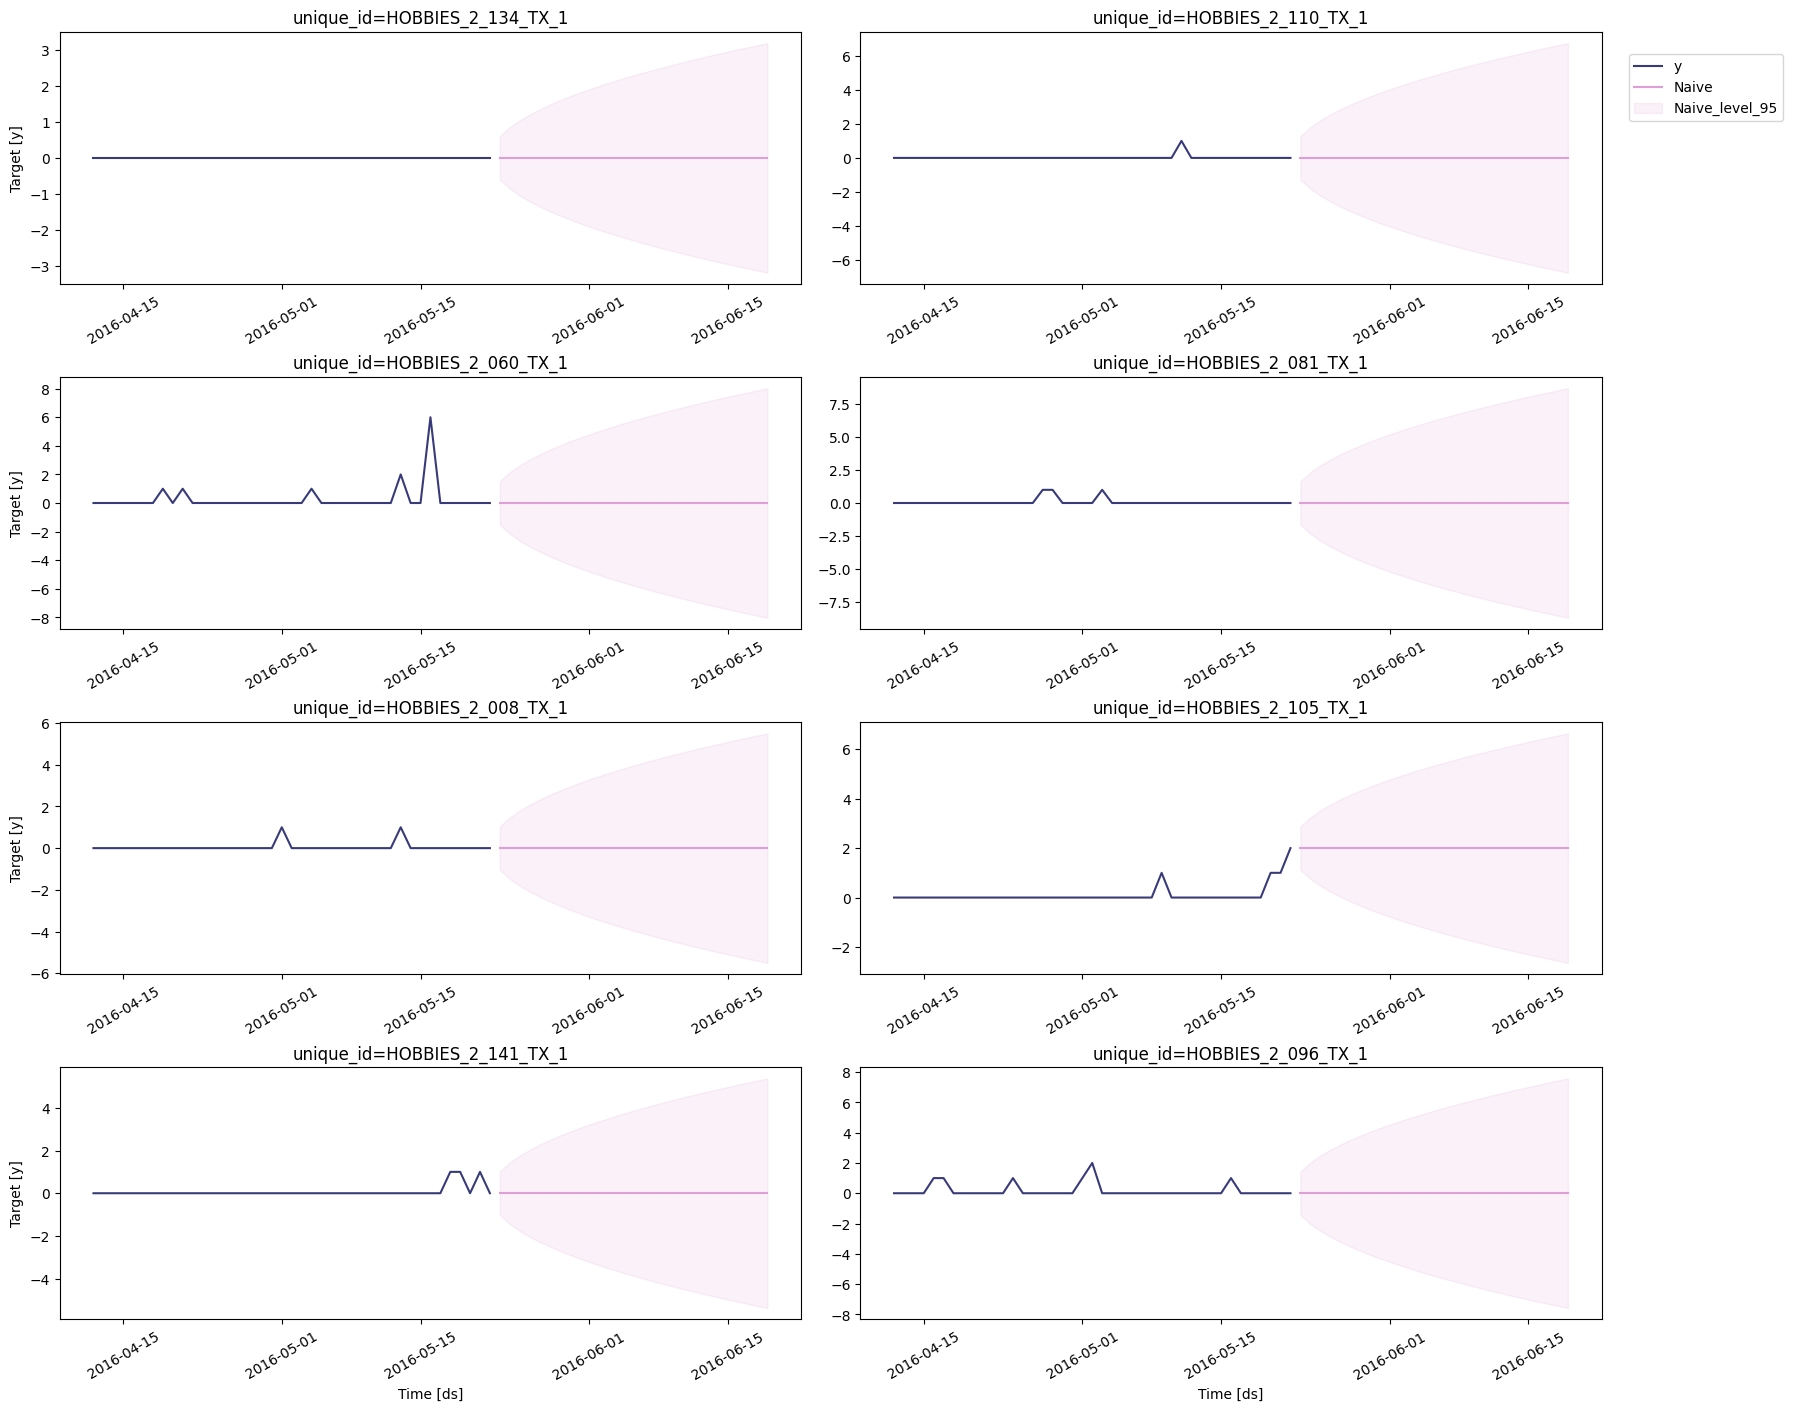

In [ ]:
sf.plot(train_last_40_days, forecasts, models=['Naive'], level=levels)

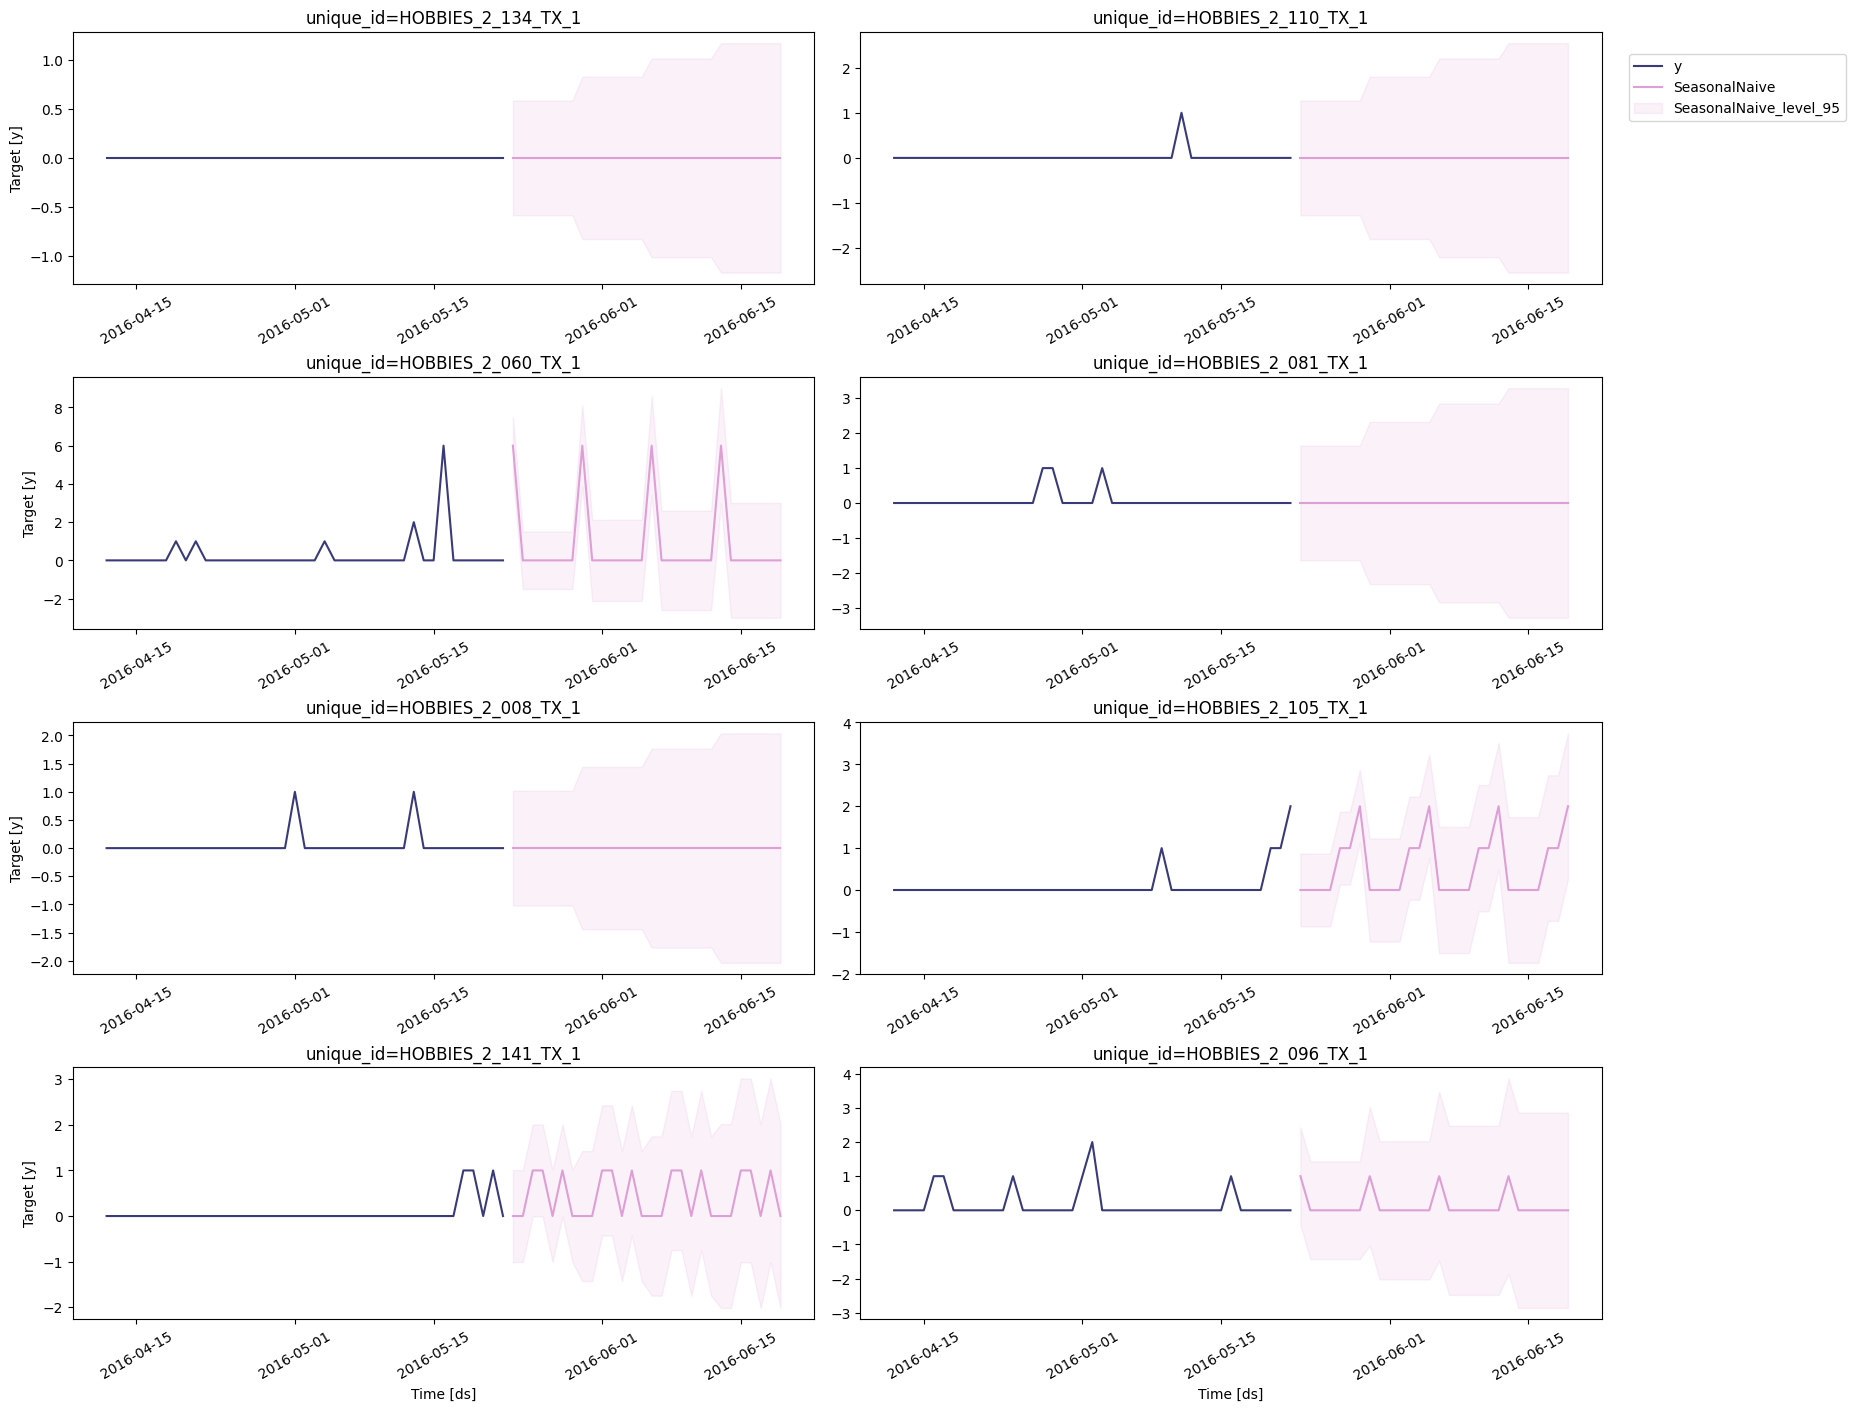

In [ ]:
sf.plot(train_last_40_days, forecasts, models=['SeasonalNaive'], level=levels)

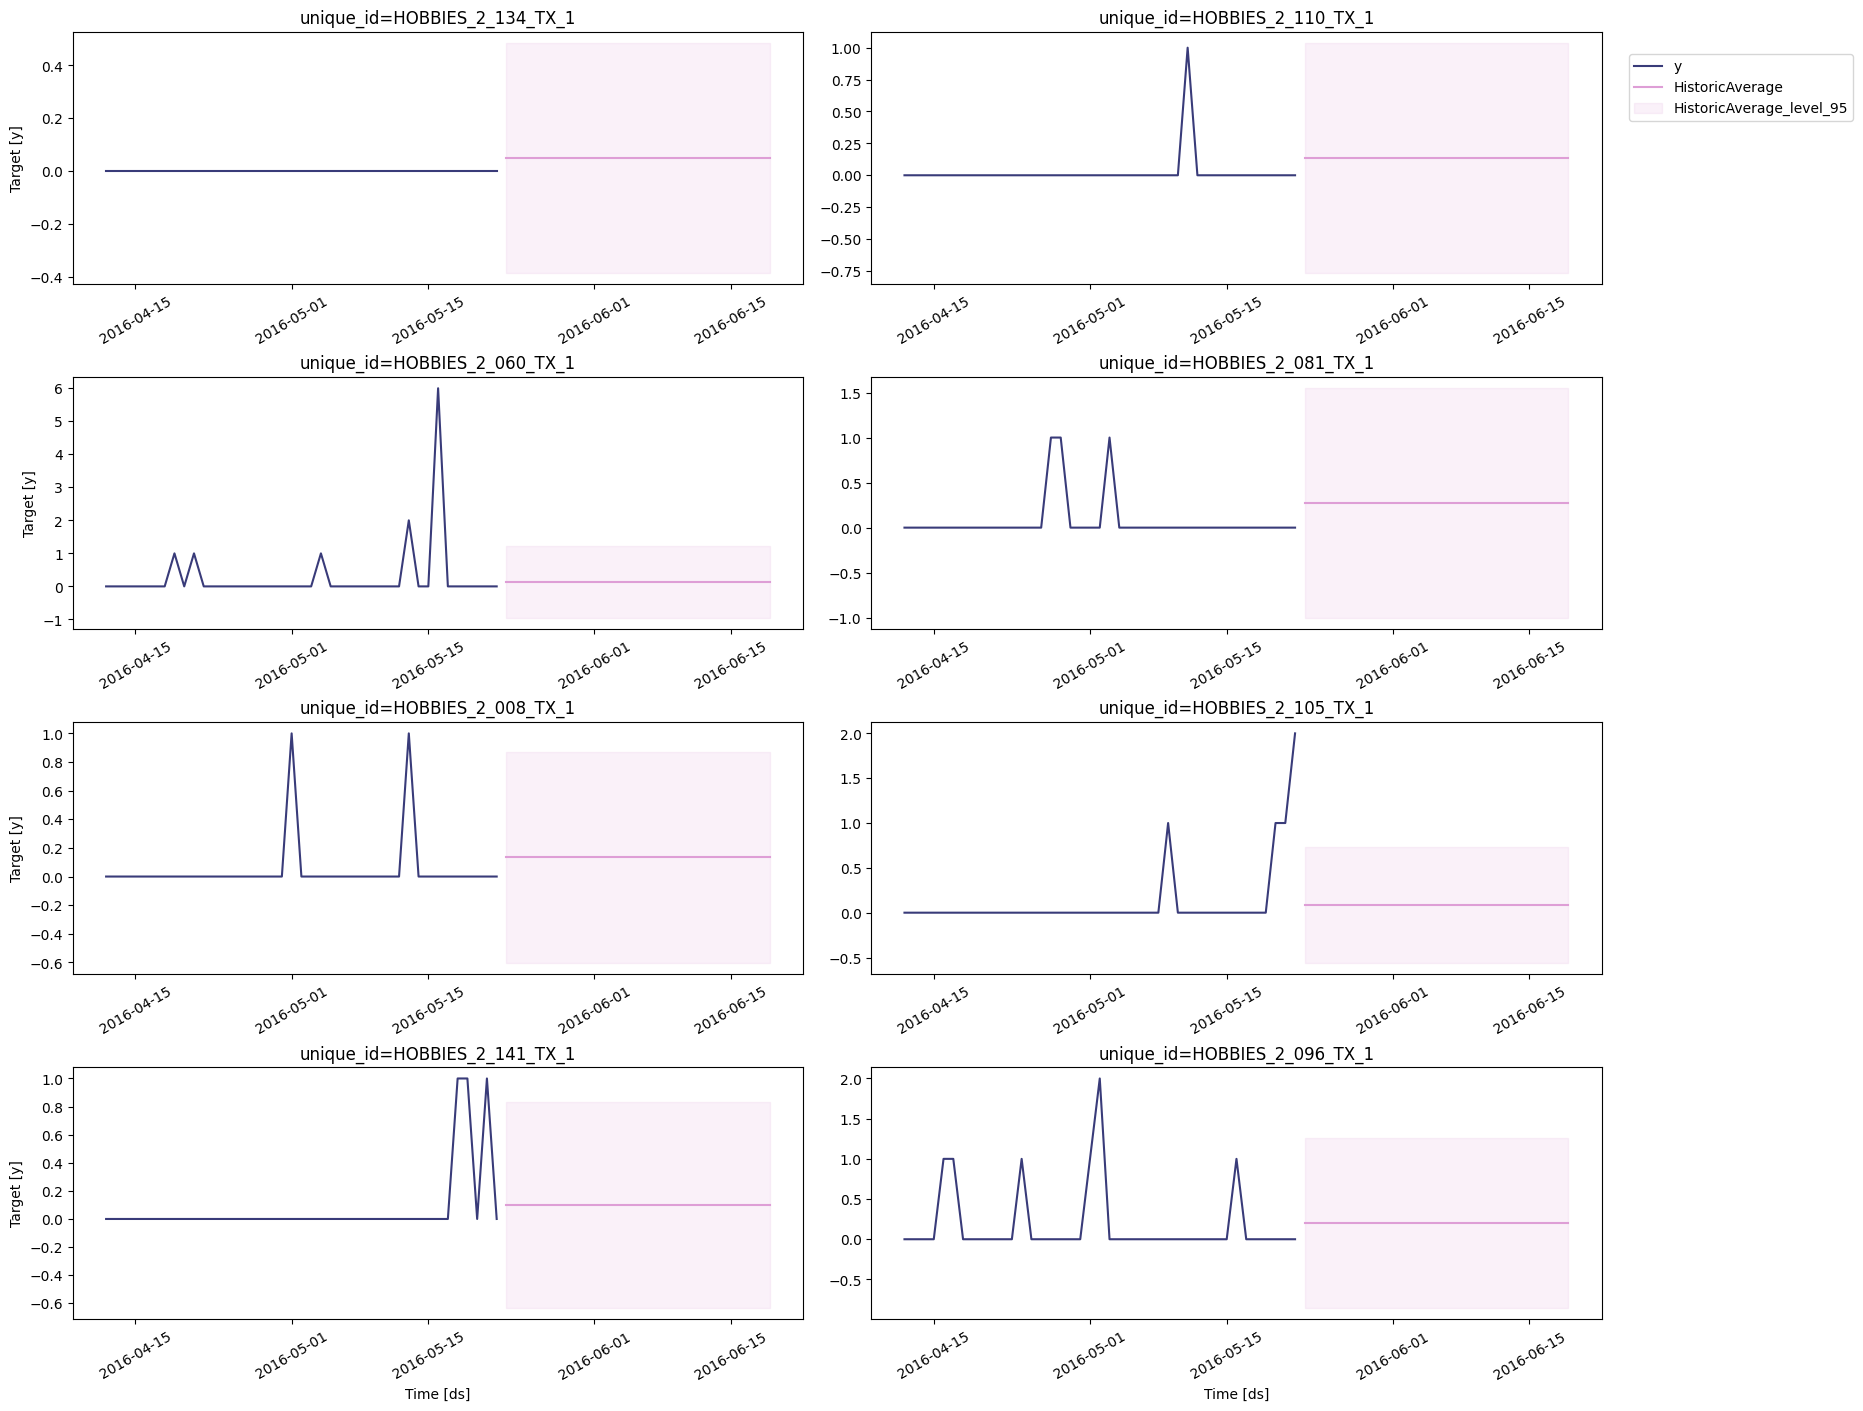

In [ ]:
sf.plot(train_last_40_days, forecasts, models=['HistoricAverage'], level=levels)

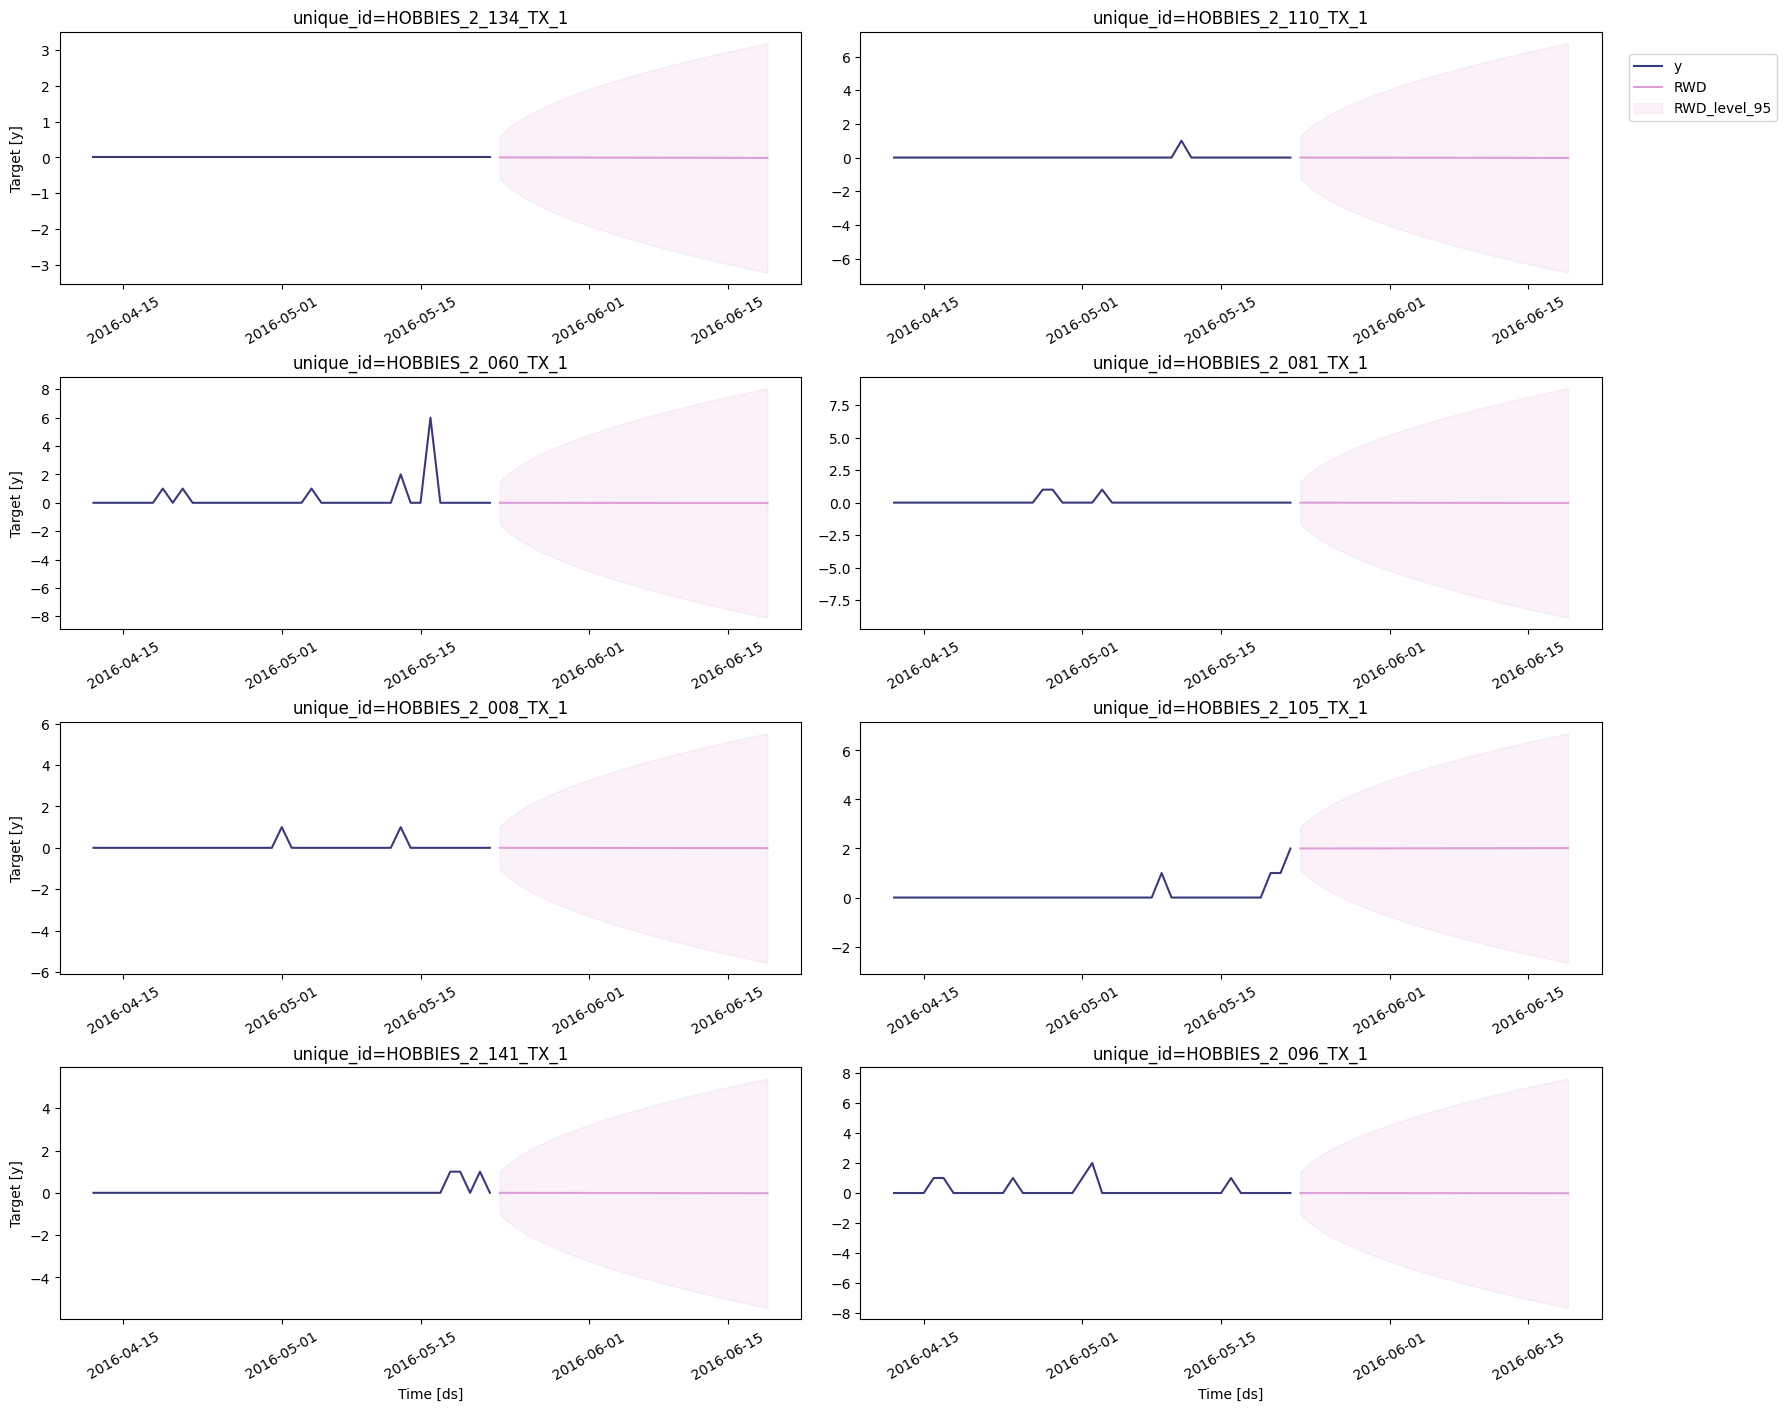

In [ ]:
sf.plot(train_last_40_days, forecasts, models=['RWD'], level=levels)

## **5. Evaluation metrics and model comparison**


In [ ]:
def rmsse(y, y_hat, y_train, seasonality):
    delta_y = np.mean((y - y_hat) ** 2)

    scale = np.mean((y_train[:-seasonality] - y_train[seasonality:]) ** 2)

    if scale < 1e-8:
        return np.nan

    return np.sqrt(delta_y / scale)


def mase(y, y_hat, y_train, seasonality):
    delta_y = np.mean(np.abs(y - y_hat))

    scale = np.mean(np.abs(y_train[:-seasonality] - y_train[seasonality:]))

    if scale < 1e-8:
        return np.nan

    return delta_y / scale


def model_evaluation(y_hist, y_true, y_pred, Model, seasonality):

    mse = metrics.mean_squared_error(y_true, y_pred)

    results_row = [{
        "Model": Model,
        "MSE": mse,
        "MAE": metrics.mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "RMSSE": rmsse(y_true.values, y_pred.values, y_hist.values, seasonality),
        "MASE": mase(y_true.values, y_pred.values, y_hist.values, seasonality)
    }]

    return pd.DataFrame(results_row)

In [ ]:
Models_results = pd.DataFrame()

model_name_mapping = {
    'Naive': 'Naive',
    'SeasonalNaive': 'SeasonalNaive',
    'HistoricAverage': 'HistoricAverage',
    'RandomWalkWithDrift': 'RWD'
}

for model in models:

    model_class_name = model.__class__.__name__
    forecast_column_name = model_name_mapping.get(model_class_name, model_class_name)

    new_result = model_evaluation(
        train["y"],
        test["y"],
        forecasts[forecast_column_name],
        model_class_name,
        season_length
    )

    Models_results = pd.concat([Models_results, new_result], ignore_index=True)

Models_results.to_csv("Results_BaselineModels.csv", index=False)

Models_results

,Model,MSE,MAE,RMSE,RMSSE,MASE
0,Naive,1.093480,0.509588,1.045696,1.108525,1.559721
1,SeasonalNaive,1.131352,0.493768,1.063650,1.127558,1.511300
2,HistoricAverage,0.433728,0.342736,0.658580,0.698150,1.049029
3,RandomWalkWithDrift,1.105867,0.522300,1.051602,1.114786,1.598628


A partir destas métricas, observamos que o modelo **`HistoricAverage`** demonstra um desempenho claramente superior aos restantes, apresentando os menores valores de **MSE, MAE, RMSE, RMSSE e MASE**. Em termos de avaliação preditiva, isto significa que as suas previsões são, em média, menos desviadas dos valores reais e apresentam menor variabilidade do erro. Os modelos **`Naive`** e **`SeasonalNaive`** surgem como alternativas razoáveis para escolhermos, com o **`SeasonalNaive`** a evidenciar ligeira vantagem devido ao menor erro absoluto, embora ambos permaneçam significativamente atrás do desempenho alcançado pelo **`HistoricAverage`**. Já o **`RandomWalkWithDrift`** revela o pior comportamento global, com erros consistentemente mais elevados, sugerindo que a inclusão de drift não contribui positivamente para a capacidade preditiva neste contexto.